In [1]:
# Week 3 - DINOv2 layer-wise Galaxy Zoo probing
%pip -q install "datasets>=3,<5" "huggingface_hub>=0.27,<2" "scikit-learn>=1.5,<2" matplotlib pandas pillow tqdm astropy nbformat


In [2]:
# importing necessary libraries
import os, json, random, gc, hashlib, contextlib, io, shutil
from pathlib import Path

os.environ["XFORMERS_DISABLED"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, TensorDataset
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


In [3]:
# Checking the selected option
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
# Turn on for caches/results to survive Colab runtime resets.
USE_DRIVE = False


Device: cuda


In [4]:
# Checking the selected option
if USE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/Week-3")
else:
    ROOT = Path("/content/Week-3")
ROOT.mkdir(parents=True, exist_ok=True)
PREPROCESS = transforms.Compose(
    [
        transforms.Resize(
            (224, 224),
            interpolation=transforms.InterpolationMode.BICUBIC,
            antialias=True,
        ),
        transforms.ToTensor(),
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)


In [5]:
# Defining amp context
def amp_context():
    return (
        torch.autocast("cuda", dtype=torch.float16)
        if DEVICE.type == "cuda"
        else contextlib.nullcontext()
    )


In [6]:
# Defining to rgb
def to_rgb(value):
    if isinstance(value, Image.Image):
        return value.convert("RGB")
    if isinstance(value, dict):
        if value.get("bytes") is not None:
            return Image.open(io.BytesIO(value["bytes"])).convert("RGB")
        if value.get("path"):
            return Image.open(value["path"]).convert("RGB")
    a = np.asarray(value)
    if a.ndim == 3 and a.shape[0] == 3 and a.shape[-1] != 3:
        a = a.transpose(1, 2, 0)
    if a.dtype != np.uint8:
        a = np.nan_to_num(a)
        if a.max() <= 1:
            a = a * 255
        a = np.clip(a, 0, 255).astype(np.uint8)
    return Image.fromarray(a).convert("RGB")


In [7]:
# importing necessary libraries
from datasets import load_dataset, concatenate_datasets
from huggingface_hub import HfApi

DATASET_ID = "MultimodalUniverse/gz10"
# Resolve exact revision, so cache metadata records the actual data source.
DATA_REVISION = HfApi().dataset_info(DATASET_ID).sha
parts = load_dataset(DATASET_ID, revision=DATA_REVISION)
# Assignment requests a fresh stratified 80/20 split of the full catalog.
ds = (
    concatenate_datasets([parts[k] for k in sorted(parts)])
    if len(parts) > 1
    else parts[next(iter(parts))]
)
IMAGE_KEY, LABEL_KEY = "rgb_image", "gz10_label"
assert IMAGE_KEY in ds.column_names and LABEL_KEY in ds.column_names, ds.column_names
print(ds, "\nColumns:", ds.column_names)
print("Dataset revision:", DATA_REVISION)


README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

gz10_rgb_images/train-00000-of-00002.par(…): reconstructing file:   0%|          |  0.00B / 1.29GB            

gz10_rgb_images/train-00000-of-00002.par(…): downloading bytes:           |  0.00B            

gz10_rgb_images/train-00001-of-00002.par(…): reconstructing file:   0%|          |  0.00B / 1.24GB            

gz10_rgb_images/train-00001-of-00002.par(…): downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

Dataset({
    features: ['gz10_label', 'redshift', 'object_id', 'rgb_image', 'rgb_pixel_scale'],
    num_rows: 17736
}) 
Columns: ['gz10_label', 'redshift', 'object_id', 'rgb_image', 'rgb_pixel_scale']
Dataset revision: eed0f087b8e3eb3316d303a8244199c2667d46fb


In [8]:
# importing necessary libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import joblib

OUT = ROOT / "results" / "probe_results"
OUT.mkdir(parents=True, exist_ok=True)
TSNE_OUT = ROOT / "results" / "tsne"
TSNE_OUT.mkdir(parents=True, exist_ok=True)
CACHE = ROOT / "cache"
CACHE.mkdir(parents=True, exist_ok=True)
BATCH_SIZE = 64


,count
0,1081
1,1853
2,2645
3,2027
4,334
5,2043
6,1829
7,2628
8,1423
9,1873


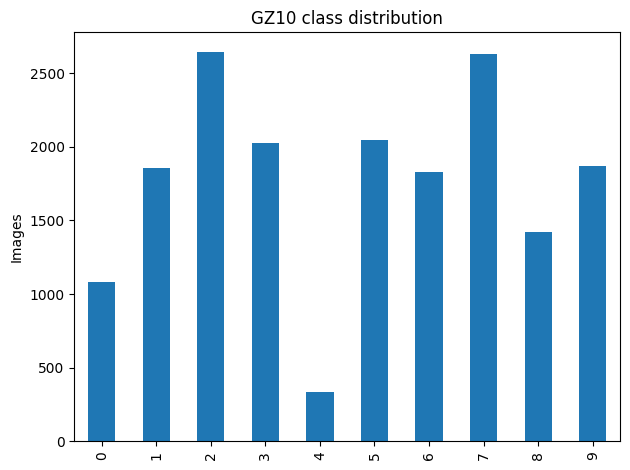

In [9]:
# Setting save patch tokens
SAVE_PATCH_TOKENS = True
# None = full catalog; use 1000 for a smoke run, never compare that result to the full-data benchmark.
MAX_IMAGES = None
y_all = np.asarray(ds[LABEL_KEY], dtype=np.int64)
if MAX_IMAGES is not None and MAX_IMAGES < len(ds):
    chosen, _ = train_test_split(
        np.arange(len(ds)), train_size=MAX_IMAGES, stratify=y_all, random_state=SEED
    )
    ds = ds.select(sorted(chosen.tolist()))
y = np.asarray(ds[LABEL_KEY], dtype=np.int64)
labels = np.unique(y)
assert np.array_equal(labels, np.arange(10)), labels
# Numeric IDs avoid attaching an unverified class-name mapping to this release.
class_names = [f"Class {i}" for i in labels]
counts = pd.Series(y).value_counts().sort_index()
display(counts.rename("count").to_frame())
counts.plot.bar(title="GZ10 class distribution")
plt.ylabel("Images")
plt.tight_layout()
plt.savefig(OUT / "class_distribution.png", dpi=180)
plt.show()
idx = np.arange(len(ds))


In [10]:
# Setting (dev idx, test idx)
dev_idx, test_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
train_idx, val_idx = train_test_split(
    dev_idx, test_size=0.2, stratify=y[dev_idx], random_state=SEED
)
np.savez(
    OUT / "split_indices.npz",
    development=dev_idx,
    train=train_idx,
    validation=val_idx,
    test=test_idx,
)
print("Train/validation/test:", len(train_idx), len(val_idx), len(test_idx))


Train/validation/test: 11350 2838 3548


In [11]:
# Frozen backbone and restartable cache
MODEL_NAME = "dinov2_vits14"
# Pin the source repository revision through GitHub's API for reproducible architecture code.
import requests

response = requests.get(
    "https://api.github.com/repos/facebookresearch/dinov2/commits/main", timeout=30
)
response.raise_for_status()
HUB_REVISION = response.json()["sha"]
model = (
    torch.hub.load(
        f"facebookresearch/dinov2:{HUB_REVISION}",
        MODEL_NAME,
        pretrained=True,
        trust_repo=True,
    )
    .eval()
    .to(DEVICE)
)


Downloading: "https://github.com/facebookresearch/dinov2/zipball/7764ea0f912e53c92e82eb78a2a1631e92725fc8" to /root/.cache/torch/hub/7764ea0f912e53c92e82eb78a2a1631e92725fc8.zip


/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:45: UserWarning: xFormers is disabled (SwiGLU)
  warnings.warn("xFormers is disabled (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:29: UserWarning: xFormers is disabled (Attention)
  warnings.warn("xFormers is disabled (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_7764ea0f912e53c92e82eb78a2a1631e92725fc8/dinov2/layers/block.py:35: UserWar

Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 263MB/s]


In [12]:
# Running the next step
for p in model.parameters():
    p.requires_grad_(False)


class GalaxyDataset(Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, i):
        return PREPROCESS(to_rgb(self.dataset[int(i)][IMAGE_KEY]))


In [13]:
# Setting loader
loader = DataLoader(
    GalaxyDataset(ds),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=DEVICE.type == "cuda",
)


In [14]:
# Setting manifest
manifest = {
    "dataset": DATASET_ID,
    "revision": DATA_REVISION,
    "fingerprint": ds._fingerprint,
    "model": MODEL_NAME,
    "hub_revision": HUB_REVISION,
    "n": len(ds),
    "layers": [9, 10, 11, 12],
    "size": 224,
    "resize": "bicubic",
    "normalization": "ImageNet",
    "dtype": "float16",
    "save_patch_tokens": SAVE_PATCH_TOKENS,
}
signature = hashlib.sha256(json.dumps(manifest, sort_keys=True).encode()).hexdigest()[
    :16
]
C = CACHE / signature
C.mkdir(exist_ok=True)
(C / "manifest.json").write_text(json.dumps(manifest, indent=2))
N, D, P = len(ds), 384, 256
shapes = {**{f"cls_L{l}": (N, D) for l in range(9, 13)}, "mean_patch_L12": (N, D)}


In [15]:
# Checking the selected option
if SAVE_PATCH_TOKENS:
    shapes.update({f"patch_L{l}": (N, P, D) for l in range(9, 13)})
required = sum(np.prod(shape) * 2 for shape in shapes.values())
missing = sum(
    np.prod(shape) * 2
    for key, shape in shapes.items()
    if not (C / f"{key}.npy").exists()
)
print(f"Cache: {C}; total {required/1e9:.2f} GB")
assert (
    shutil.disk_usage(C).free > missing + 500_000_000
), "Not enough space; use Drive or disable full patch cache."
all_cache_files_present = all((C / f"{key}.npy").exists() for key in shapes)
arrays = {}


Cache: /content/Week-3/cache/b99da374475af154; total 14.02 GB


In [16]:
# Running the next step
for key, shape in shapes.items():
    path = C / f"{key}.npy"
    arrays[key] = (
        np.load(path, mmap_mode="r+")
        if path.exists()
        else np.lib.format.open_memmap(path, mode="w+", dtype=np.float16, shape=shape)
    )
    assert arrays[key].shape == shape
progress = C / "completed.json"
start = (
    json.loads(progress.read_text())["rows"]
    if progress.exists() and all_cache_files_present
    else 0
)
assert 0 <= start <= N


In [17]:
# Resume by skipping already committed batches; progress is written only AFTER flushing every array.
with torch.inference_mode():
    for batch_no, x in enumerate(tqdm(loader, desc="Extract layers 9–12")):
        lo = batch_no * BATCH_SIZE
        hi = lo + len(x)
        if hi <= start:
            continue
        with amp_context():
            outputs = model.get_intermediate_layers(
                x.to(DEVICE, non_blocking=True), n=4, return_class_token=True
            )
        for layer, (patch, cls) in zip(range(9, 13), outputs):
            assert patch.shape[1:] == (256, 384) and cls.shape[1:] == (384,)
            arrays[f"cls_L{layer}"][lo:hi] = cls.float().cpu().numpy()
            if SAVE_PATCH_TOKENS:
                arrays[f"patch_L{layer}"][lo:hi] = patch.float().cpu().numpy()
            if layer == 12:
                arrays["mean_patch_L12"][lo:hi] = patch.float().mean(1).cpu().numpy()
        for a in arrays.values():
            a.flush()
        temp = C / "completed.tmp"
        temp.write_text(json.dumps({"rows": hi}))
        temp.replace(progress)


Extract layers 9–12:   0%|          | 0/278 [00:00<?, ?it/s]

In [18]:
# Processing the data
np.save(C / "labels.npy", y)
assert json.loads(progress.read_text())["rows"] == N
features = {
    key: np.asarray(arrays[key], dtype=np.float32)
    for key in shapes
    if not key.startswith("patch_")
}
features["concat_CLS_L9_L12"] = np.concatenate(
    [features[f"cls_L{l}"] for l in range(9, 13)], axis=1
)
np.save(C / "concat_CLS_L9_L12.npy", features["concat_CLS_L9_L12"])
assert all(np.isfinite(a).all() for a in features.values())
del model
gc.collect()


3671

In [19]:
# Checking the selected option
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
print({k: v.shape for k, v in features.items()})


{'cls_L9': (17736, 384), 'cls_L10': (17736, 384), 'cls_L11': (17736, 384), 'cls_L12': (17736, 384), 'mean_patch_L12': (17736, 384), 'concat_CLS_L9_L12': (17736, 1536)}


In [20]:
# Probe implementations
def fit_probe(kind, X, y_train, seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    if kind == "Linear":
        return LogisticRegression(C=1.0, max_iter=3000, solver="lbfgs").fit(X, y_train)
    net = torch.nn.Sequential(
        torch.nn.Linear(X.shape[1], 256), torch.nn.ReLU(), torch.nn.Linear(256, 10)
    ).to(DEVICE)
    optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)
    generator = torch.Generator().manual_seed(seed)
    dl = DataLoader(
        TensorDataset(
            torch.from_numpy(np.asarray(X, dtype=np.float32)),
            torch.from_numpy(y_train.astype(np.int64)),
        ),
        batch_size=64,
        shuffle=True,
        generator=generator,
    )
    net.train()
    for epoch in range(30):
        loss_total = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            loss = F.cross_entropy(net(xb), yb)
            loss.backward()
            optimizer.step()
            loss_total += loss.item() * len(xb)
        if (epoch + 1) % 10 == 0:
            print(f"  epoch {epoch+1:02d}: train loss {loss_total/len(X):.4f}")
    return net.eval()


In [21]:
# Defining predict probe
def predict_probe(probe, X):
    if isinstance(probe, LogisticRegression):
        return probe.predict(X)
    chunks = []
    with torch.inference_mode():
        for lo in range(0, len(X), 512):
            xb = torch.from_numpy(np.asarray(X[lo : lo + 512], dtype=np.float32)).to(
                DEVICE
            )
            chunks.append(probe(xb).argmax(1).cpu().numpy())
    return np.concatenate(chunks)


In [22]:
# Defining metrics
def metrics(y_true, pred):
    return {
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
    }


In [23]:
# Setting validation rows
validation_rows = []
for feature_name, X in tqdm(features.items(), desc="Validation: six feature sets"):
    scaler = StandardScaler().fit(X[train_idx])
    Xtr = scaler.transform(X[train_idx]).astype(np.float32)
    Xval = scaler.transform(X[val_idx]).astype(np.float32)
    for kind in ["Linear", "MLP"]:
        print(feature_name, kind)
        probe = fit_probe(kind, Xtr, y[train_idx])
        pred = predict_probe(probe, Xval)
        validation_rows.append(
            {"feature": feature_name, "probe": kind, **metrics(y[val_idx], pred)}
        )
        del probe
validation = pd.DataFrame(validation_rows).sort_values(
    ["accuracy", "macro_f1"], ascending=False
)
validation.to_csv(OUT / "validation_results.csv", index=False)
display(validation)
selected = validation.iloc[0]
print("Selected using validation only:", selected["feature"], selected["probe"])


Validation: six feature sets:   0%|          | 0/6 [00:00<?, ?it/s]

cls_L9 Linear
cls_L9 MLP
  epoch 10: train loss 0.6063
  epoch 20: train loss 0.3257
  epoch 30: train loss 0.1610
cls_L10 Linear
cls_L10 MLP
  epoch 10: train loss 0.5701
  epoch 20: train loss 0.2686
  epoch 30: train loss 0.1102
cls_L11 Linear
cls_L11 MLP
  epoch 10: train loss 0.5239
  epoch 20: train loss 0.2369
  epoch 30: train loss 0.1010
cls_L12 Linear
cls_L12 MLP
  epoch 10: train loss 0.4991
  epoch 20: train loss 0.2167
  epoch 30: train loss 0.0981
mean_patch_L12 Linear
mean_patch_L12 MLP
  epoch 10: train loss 0.5433
  epoch 20: train loss 0.2233
  epoch 30: train loss 0.0899
concat_CLS_L9_L12 Linear
concat_CLS_L9_L12 MLP
  epoch 10: train loss 0.3599
  epoch 20: train loss 0.1382
  epoch 30: train loss 0.0609


,feature,probe,accuracy,balanced_accuracy,macro_f1
4,cls_L11,Linear,0.692741,0.661967,0.662849
10,concat_CLS_L9_L12,Linear,0.691332,0.664864,0.665721
6,cls_L12,Linear,0.682523,0.659576,0.663928
11,concat_CLS_L9_L12,MLP,0.674419,0.640921,0.644748
2,cls_L10,Linear,0.673362,0.630979,0.633732
0,cls_L9,Linear,0.671952,0.628391,0.631591
5,cls_L11,MLP,0.666667,0.641857,0.644017
8,mean_patch_L12,Linear,0.661381,0.627434,0.629862
7,cls_L12,MLP,0.657858,0.631327,0.635662
1,cls_L9,MLP,0.639183,0.600989,0.607562


Selected using validation only: cls_L11 Linear


In [24]:
# Refit on 80%, evaluate all settings on the fixed 20%
test_rows = []
predictions = {}


In [25]:
# Running the next step
for feature_name, X in tqdm(features.items(), desc="Final test evaluation"):
    scaler = StandardScaler().fit(X[dev_idx])
    Xdev = scaler.transform(X[dev_idx]).astype(np.float32)
    Xtest = scaler.transform(X[test_idx]).astype(np.float32)
    for kind in ["Linear", "MLP"]:
        probe = fit_probe(kind, Xdev, y[dev_idx])
        pred = predict_probe(probe, Xtest)
        predictions[(feature_name, kind)] = pred
        test_rows.append(
            {"feature": feature_name, "probe": kind, **metrics(y[test_idx], pred)}
        )
        report = classification_report(
            y[test_idx],
            pred,
            labels=labels,
            target_names=class_names,
            output_dict=True,
            zero_division=0,
        )
        pd.DataFrame(report).T.to_csv(OUT / f"{feature_name}_{kind}_per_class.csv")
        if feature_name == selected["feature"] and kind == selected["probe"]:
            joblib.dump(scaler, OUT / "best_scaler.joblib")
            if kind == "Linear":
                joblib.dump(probe, OUT / "best_linear.joblib")
            else:
                torch.save(
                    {k: v.cpu() for k, v in probe.state_dict().items()},
                    OUT / "best_mlp.pt",
                )
        del probe


Final test evaluation:   0%|          | 0/6 [00:00<?, ?it/s]

  epoch 10: train loss 0.6243
  epoch 20: train loss 0.3666
  epoch 30: train loss 0.1912
  epoch 10: train loss 0.5888
  epoch 20: train loss 0.3056
  epoch 30: train loss 0.1436
  epoch 10: train loss 0.5392
  epoch 20: train loss 0.2668
  epoch 30: train loss 0.1227
  epoch 10: train loss 0.5143
  epoch 20: train loss 0.2412
  epoch 30: train loss 0.1077
  epoch 10: train loss 0.5623
  epoch 20: train loss 0.2610
  epoch 30: train loss 0.1096
  epoch 10: train loss 0.4042
  epoch 20: train loss 0.1702
  epoch 30: train loss 0.1498


In [26]:
# Setting results
results = pd.DataFrame(test_rows)
results.to_csv(OUT / "test_results.csv", index=False)
display(
    results.pivot(index="feature", columns="probe", values="accuracy").style.format(
        "{:.2%}"
    )
)
selected_key = (selected["feature"], selected["probe"])
best_pred = predictions[selected_key]
np.savez(
    OUT / "test_predictions.npz",
    y_true=y[test_idx],
    **{f"{a}__{b}": p for (a, b), p in predictions.items()},
)


probe,Linear,MLP
feature,,
cls_L10,67.47%,64.26%
cls_L11,69.05%,66.12%
cls_L12,69.00%,66.07%
cls_L9,67.50%,64.88%
concat_CLS_L9_L12,68.83%,67.87%
mean_patch_L12,66.15%,63.08%


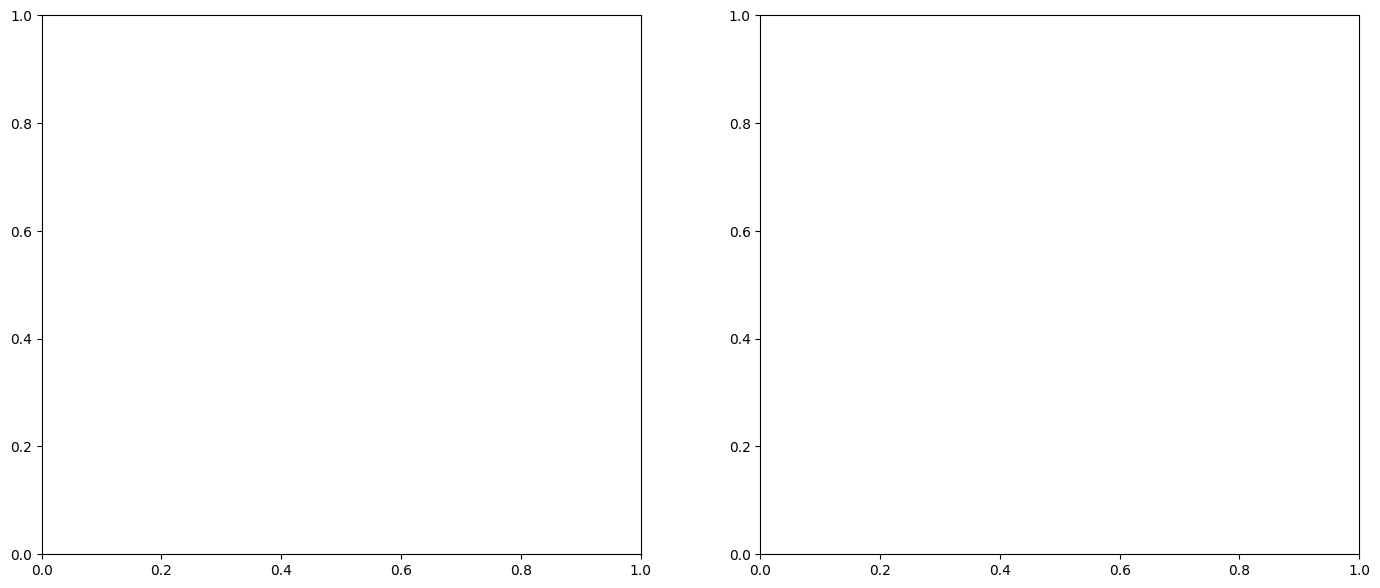

In [27]:
# Processing the data
(OUT / "selected_setting.json").write_text(
    json.dumps(
        {
            "feature": selected_key[0],
            "probe": selected_key[1],
            "selection": "validation accuracy, macro F1 tie break",
            "seed": SEED,
            "manifest": manifest,
        },
        indent=2,
    )
)
fig, axes = plt.subplots(1, 2, figsize=(17, 7))


In [28]:
# Running the next step
for ax, norm in zip(axes, [None, "true"]):
    ConfusionMatrixDisplay.from_predictions(
        y[test_idx],
        best_pred,
        labels=labels,
        display_labels=labels,
        normalize=norm,
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d" if norm is None else ".2f",
    )
    ax.set_title(
        "Counts" if norm is None else "Row-normalized: per-class accuracy on diagonal"
    )
fig.suptitle(f"Validation-selected: {selected_key}")
fig.tight_layout()
fig.savefig(OUT / "best_confusion_matrix.png", dpi=180)
plt.show()


In [29]:
# Setting report
report = classification_report(
    y[test_idx],
    best_pred,
    labels=labels,
    target_names=class_names,
    output_dict=True,
    zero_division=0,
)
per_class = (
    pd.DataFrame(report)
    .T.iloc[:10][["precision", "recall", "f1-score", "support"]]
    .rename(columns={"recall": "per_class_accuracy"})
)
display(per_class)
per_class.to_csv(OUT / "best_per_class_accuracy.csv")


,precision,per_class_accuracy,f1-score,support
Class 0,0.423358,0.268519,0.328612,216.0
Class 1,0.657895,0.673854,0.665779,371.0
Class 2,0.771777,0.837429,0.803264,529.0
Class 3,0.708241,0.785185,0.744731,405.0
Class 4,0.538462,0.417910,0.470588,67.0
Class 5,0.688347,0.621027,0.652956,409.0
Class 6,0.650407,0.655738,0.653061,366.0
Class 7,0.551167,0.583650,0.566944,526.0
Class 8,0.824916,0.862676,0.843373,284.0
Class 9,0.843407,0.818667,0.830853,375.0


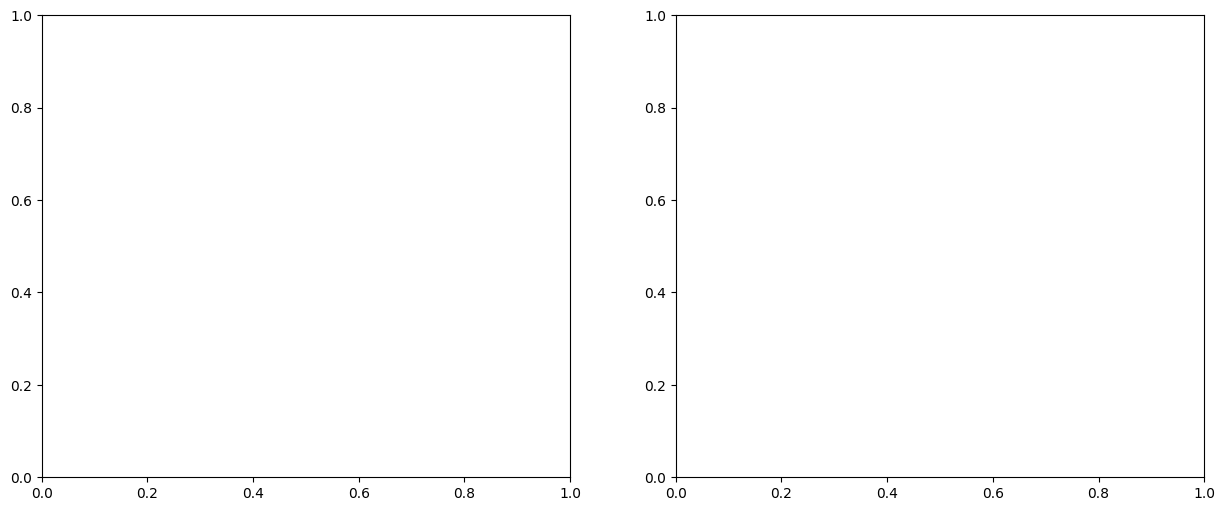

In [30]:
# t-SNE: last layer versus validation-selected best individual CLS layer
layer_rows = validation[validation.feature.isin([f"cls_L{l}" for l in range(9, 13)])]
best_layer = layer_rows.iloc[0]["feature"]
if len(test_idx) > 2000:
    vis_idx, _ = train_test_split(
        test_idx, train_size=2000, stratify=y[test_idx], random_state=SEED
    )
else:
    vis_idx = test_idx
fig, axes = plt.subplots(1, 2, figsize=(15, 6))


In [31]:
# Running the next step
for ax, key in zip(axes, ["cls_L12", best_layer]):
    X = features[key]
    scaler = StandardScaler().fit(X[dev_idx])
    pca = PCA(n_components=min(50, X.shape[1], len(dev_idx)), random_state=SEED)
    pca.fit(scaler.transform(X[dev_idx]))
    z = pca.transform(scaler.transform(X[vis_idx]))
    embed = TSNE(
        n_components=2,
        perplexity=min(30, (len(z) - 1) / 3),
        init="pca",
        learning_rate="auto",
        random_state=SEED,
    ).fit_transform(z)
    scatter = ax.scatter(
        embed[:, 0],
        embed[:, 1],
        c=y[vis_idx],
        cmap="tab10",
        vmin=-0.5,
        vmax=9.5,
        s=6,
        alpha=0.8,
    )
    ax.set_title(key + (" (best individual CLS layer)" if key == best_layer else ""))
    ax.set_xticks([])
    ax.set_yticks([])
    np.savez(
        TSNE_OUT / f"{key}.npz", embedding=embed, indices=vis_idx, labels=y[vis_idx]
    )


In [32]:
# Visualizing the results
fig.colorbar(scatter, ax=axes.ravel().tolist(), ticks=range(10), label="GZ10 class ID")
fig.savefig(TSNE_OUT / "last_vs_best_layer.png", dpi=200, bbox_inches="tight")
plt.show()
print("Best individual CLS layer by validation:", best_layer)


Best individual CLS layer by validation: cls_L11


In [33]:
# Report-ready numerical summary and download
best_result = results[
    (results.feature == selected_key[0]) & (results.probe == selected_key[1])
].iloc[0]
base = results[(results.feature == "cls_L12") & (results.probe == "MLP")].iloc[0]
cm = confusion_matrix(y[test_idx], best_pred, labels=labels)
np.fill_diagonal(cm, 0)
confusions = sorted(
    [(int(cm[a, b]), int(a), int(b)) for a in range(10) for b in range(10) if a != b],
    reverse=True,
)[:5]


In [34]:
# Setting text
text = f"""# Week 3 measured summary
Dataset: {len(ds)} images; seed {SEED}; test images {len(test_idx)}.
Selected on validation: {selected_key[0]} + {selected_key[1]}.
Selected-setting test accuracy: {best_result.accuracy:.2%}.
Selected-setting test balanced accuracy: {best_result.balanced_accuracy:.2%}.
Selected-setting test macro F1: {best_result.macro_f1:.4f}.
Best individual CLS layer on validation: {best_layer}.
L12 CLS + MLP test accuracy: {base.accuracy:.2%}.
Assignment reference: ViT-S/14 67%; ViT-L/14 73% (not reproduced here).
Reference values are from Week3.pdf; exact comparability depends on preprocessing,
split, training recipe, and checkpoint. This is a single-seed estimate.
Most frequent directed confusions (count, true class, predicted class): {confusions}.

Add your own attention observations and inspect examples of confused classes before
claiming a visual reason. Class IDs are authoritative; verify semantic class names
against this dataset release. Do not interpret t-SNE separation as a test metric.
"""
(OUT / "measured_summary.md").write_text(text)
print(text)
# Exclude large feature caches from download; enable Drive to retain those.
archive = shutil.make_archive("/content/Week3_probe_results", "zip", ROOT / "results")
from google.colab import files


# Week 3 measured summary
Dataset: 17736 images; seed 42; test images 3548.
Selected on validation: cls_L11 + Linear.
Selected-setting test accuracy: 69.05%.
Selected-setting test balanced accuracy: 65.25%.
Selected-setting test macro F1: 0.6560.
Best individual CLS layer on validation: cls_L11.
L12 CLS + MLP test accuracy: 66.07%.
Assignment reference: ViT-S/14 67%; ViT-L/14 73% (not reproduced here).
Reference values are from Week3.pdf; exact comparability depends on preprocessing,
split, training recipe, and checkpoint. This is a single-seed estimate.
Most frequent directed confusions (count, true class, predicted class): [(71, 6, 7), (70, 5, 7), (60, 7, 6), (54, 7, 5), (46, 0, 7)].

Add your own attention observations and inspect examples of confused classes before
claiming a visual reason. Class IDs are authoritative; verify semantic class names
against this dataset release. Do not interpret t-SNE separation as a test metric.



In [35]:
# Processing the data
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>